In [4]:
import os
from pathlib import Path
import sys

import h3
import h3pandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pydeck as pdk
import seaborn as sns
from shapely.geometry import shape
from sklearn.metrics import precision_score, recall_score, f1_score
import tensorflow as tf
from tqdm.auto import tqdm

sns.set()

2025-05-08 08:23:41.466901: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-05-08 08:23:41.466932: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-05-08 08:23:41.468042: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-05-08 08:23:41.473545: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-05-08 08:23:42.013706: W tensorflow/compiler/tf2

In [5]:
sys.path.append('..')
from lib.models.tf_gp_model import TFGeoPriorModel
from lib.models.encoders import CoordEncoder

In [3]:
GEOMODEL_PATH = "/home/alex/inatGeoModelTraining/saved_models/saved_model_sinr_coords.h5"
ELEVATION_RASTER_PATH = "/home/alex/sinr/data/env/elev_scaled.npy"
INPUT_ENCODING = "sinusoidal"
TAX_SINR_FILE = "/home/alex/sinr/data/train/sinr_taxonomy.csv"
TARGET_TAXON_ID = 13270

In [4]:
model = TFGeoPriorModel(GEOMODEL_PATH)
encoder = CoordEncoder(INPUT_ENCODING, raster=None)
tax = pd.read_csv(TAX_SINR_FILE)

2025-05-08 08:14:47.895402: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-08 08:14:47.925275: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2025-05-08 08:14:47.926687: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:901] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [5]:
res0_cells = h3.get_res0_indexes()
all_cells = set()
for res0 in tqdm(res0_cells):
    children = h3.h3_to_children(res0, 4)
    all_cells.update(children)
    
cells_df = pd.DataFrame({"h3_04": list(all_cells)})
cells_df.set_index("h3_04", inplace=True)

dfh3 = cells_df.h3.h3_to_geo()
dfh3["lng"] = dfh3.geometry.x
dfh3["lat"] = dfh3.geometry.y
_ = dfh3.pop("geometry")

  0%|          | 0/122 [00:00<?, ?it/s]

In [6]:
target_class_id = tax[tax.taxon_id==TARGET_TAXON_ID].iloc[0].leaf_class_id

In [7]:
locs = dfh3[["lng", "lat"]].values
encoded_locs = encoder.encode(locs)
geo_model_features = model.get_loc_emb(encoded_locs)
preds = model.eval_one_class_from_feats(
    geo_model_features,
    class_of_interest=target_class_id
)

In [8]:
preds

array([[1.3931920e-20, 3.4794226e-26, 6.6589554e-21, ..., 2.6569924e-07,
        2.4215131e-05, 8.7274582e-04]], dtype=float32)

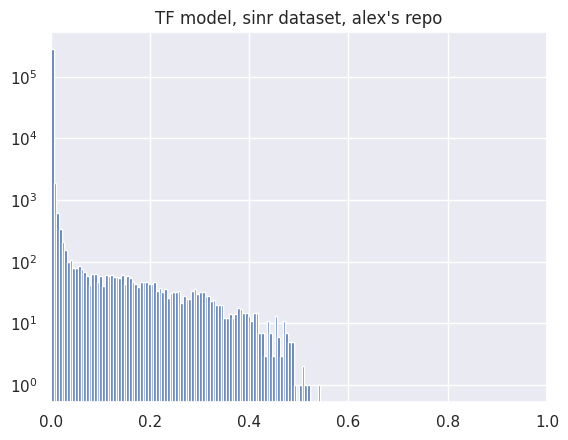

In [17]:
preds_series = pd.Series(preds[0])
ax = preds_series.hist(bins=100)
ax.set_yscale("log")
ax.set_title("TF model, sinr dataset, alex's repo")
ax.set_xlim([0, 1])
plt.show()

# ok let's try it with the 2.21 model

In [6]:
GEOMODEL_PATH = "/home/alex/inatGeoModelTraining/saved_models/saved_model_2_21_coords_elev.h5"
ELEVATION_RASTER_PATH = "/home/alex/sinr/data/env/elev_scaled.npy"
INPUT_ENCODING = "sinusoidal"
TAX_FILE = "/data-ssd/alex/datasets/vision-export-20250216070017-aka-2.21/taxonomy.csv"
TARGET_TAXON_ID = 13270

In [8]:
model = TFGeoPriorModel(GEOMODEL_PATH)
raster = np.load(ELEVATION_RASTER_PATH).astype(np.float32)
encoder = CoordEncoder(INPUT_ENCODING, raster=raster)
tax = pd.read_csv(TAX_FILE)

In [9]:
res0_cells = h3.get_res0_indexes()
all_cells = set()
for res0 in tqdm(res0_cells):
    children = h3.h3_to_children(res0, 4)
    all_cells.update(children)
    
cells_df = pd.DataFrame({"h3_04": list(all_cells)})
cells_df.set_index("h3_04", inplace=True)

dfh3 = cells_df.h3.h3_to_geo()
dfh3["lng"] = dfh3.geometry.x
dfh3["lat"] = dfh3.geometry.y
_ = dfh3.pop("geometry")

  0%|          | 0/122 [00:00<?, ?it/s]

In [14]:
target_class_id = int(tax[tax.taxon_id==TARGET_TAXON_ID].iloc[0].leaf_class_id)

In [15]:
locs = dfh3[["lng", "lat"]].values
encoded_locs = encoder.encode(locs)
geo_model_features = model.get_loc_emb(encoded_locs)
preds = model.eval_one_class_from_feats(
    geo_model_features,
    class_of_interest=target_class_id
)

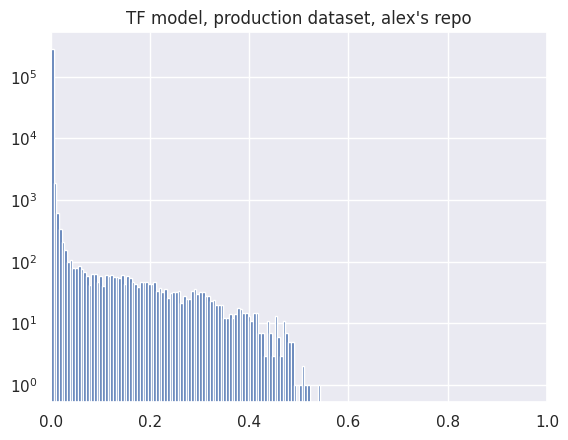

In [18]:
preds_series = pd.Series(preds[0])
ax = preds_series.hist(bins=100)
ax.set_yscale("log")
ax.set_title("TF model, production dataset, alex's repo")
ax.set_xlim([0, 1])
plt.show()